<a href="https://colab.research.google.com/github/DawitMerdassa/Montgomery-College-Enrollment-2015/blob/main/montgomery_college_enrollment_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

from google.colab import files
import pandas as pd
import matplotlib.pyplot as plt

uploaded = files.upload()
filename = next(iter(uploaded))

df = pd.read_csv(filename)

print("File loaded:", filename)
print("Dataset dimensions:", df.shape)

display(df.head())

Saving Montgomery_College_Enrollment_Data_20261022.csv to Montgomery_College_Enrollment_Data_20261022 (2).csv
File loaded: Montgomery_College_Enrollment_Data_20261022 (2).csv
Dataset dimensions: (25320, 18)


,Fall Term,Student Type,Student Status,Gender,Ethnicity,Race,Attending Germantown,Attending Rockville,Attending Takoma Park/SS,Attend Day or Evening,MC Program Description,Age Group,HS Category,MCPS High School,City in MD,State,ZIP,County in MD
0,2015,Continuing,Full-Time,Female,Not Hispanic,White,Yes,Yes,No,Day Only,Health Sciences (Pre-Clinical Studies),25 - 29,Foreign Country,NaN,Bethesda,MD,20816.0,Montgomery
1,2015,Continuing,Part-Time,Male,Not Hispanic,White,No,Yes,No,Evening Only,Building Trades Technology (AA & AAS),21 - 24,MCPS,Sherwood High School,Olney,MD,20832.0,Montgomery
2,2015,Continuing,Part-Time,Male,Not Hispanic,Black,No,Yes,No,Day & Evening,Computer Gaming & Simulation (AA - All Tracks),20 or Younger,MCPS,Quince Orchard Sr High School,Gaithersburg,MD,20877.0,Montgomery
3,2015,New,Full-Time,Male,Not Hispanic,Asian,No,Yes,No,Day Only,"Graphic Design (AA, AAS, & AFA - All Tracks)",20 or Younger,MCPS,Thomas Sprigg Wootton High Sch,North Potomac,MD,20878.0,Montgomery
4,2015,New,Full-Time,Female,Hispanic,White,No,Yes,No,Day & Evening,General Studies (AA - All Tracks),20 or Younger,MCPS,Montgomery Blair High School,Silver Spring,MD,20906.0,Montgomery


In [ ]:
# Check data types and non-missing values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25320 entries, 0 to 25319
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Fall Term                 25320 non-null  int64  
 1   Student Type              25320 non-null  object 
 2   Student Status            25320 non-null  object 
 3   Gender                    25320 non-null  object 
 4   Ethnicity                 25320 non-null  object 
 5   Race                      25320 non-null  object 
 6   Attending Germantown      25320 non-null  object 
 7   Attending Rockville       25320 non-null  object 
 8   Attending Takoma Park/SS  25320 non-null  object 
 9   Attend Day or Evening     25320 non-null  object 
 10  MC Program Description    25320 non-null  object 
 11  Age Group                 25320 non-null  object 
 12  HS Category               25320 non-null  object 
 13  MCPS High School          13558 non-null  object 
 14  City i

In [ ]:
# Check missing values
print("\nMissing values by column:")
print(df.isna().sum())


Missing values by column:
Fall Term                       0
Student Type                    0
Student Status                  0
Gender                          0
Ethnicity                       0
Race                            0
Attending Germantown            0
Attending Rockville             0
Attending Takoma Park/SS        0
Attend Day or Evening           0
MC Program Description          0
Age Group                       0
HS Category                     0
MCPS High School            11762
City in MD                     97
State                           8
ZIP                            99
County in MD                    0
dtype: int64


In [ ]:
# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())


Duplicate rows: 1117


In [ ]:
# Check possible year/date columns
print("\nPossible year/date columns:")
print([
    col for col in df.columns
    if "year" in col.lower() or "date" in col.lower()
])


Possible year/date columns:
[]


In [ ]:
# Review the categories used in the project
columns = [
    "Gender",
    "Race",
    "MC Program Description",
    "Age Group",
    "Attend Day or Evening",
    "City in MD"
]

for col in columns:
    if col in df.columns:
        print(f"\n{col}")
        print(df[col].value_counts(dropna=False).head(15))


Gender
Gender
Female     13350
Male       11963
Unknown        7
Name: count, dtype: int64

Race
Race
White               9831
Black               8217
Asian               3538
Hispanic            2028
Multi-Race           860
Native American      501
Pacific Islander     293
Unknown               52
Name: count, dtype: int64

MC Program Description
MC Program Description
General Studies (AA - All Tracks)                    7449
Health Sciences (Pre-Clinical Studies)               2969
Business / International Business (AA)               2289
Engineering Science (AA & AS - All Tracks)           1482
Science (AS - All Tracks)                            1432
Arts & Sciences Transfer (AA - All Tracks)           1134
Credit (Undeclared / Undecided)                      1127
Computer Science & Technologies (AA - All Tracks)     866
Education / Teacher Education (AA & AAT)              845
Criminal Justice (AA & AAS)                           638
Nursing (AA & AAS)                          

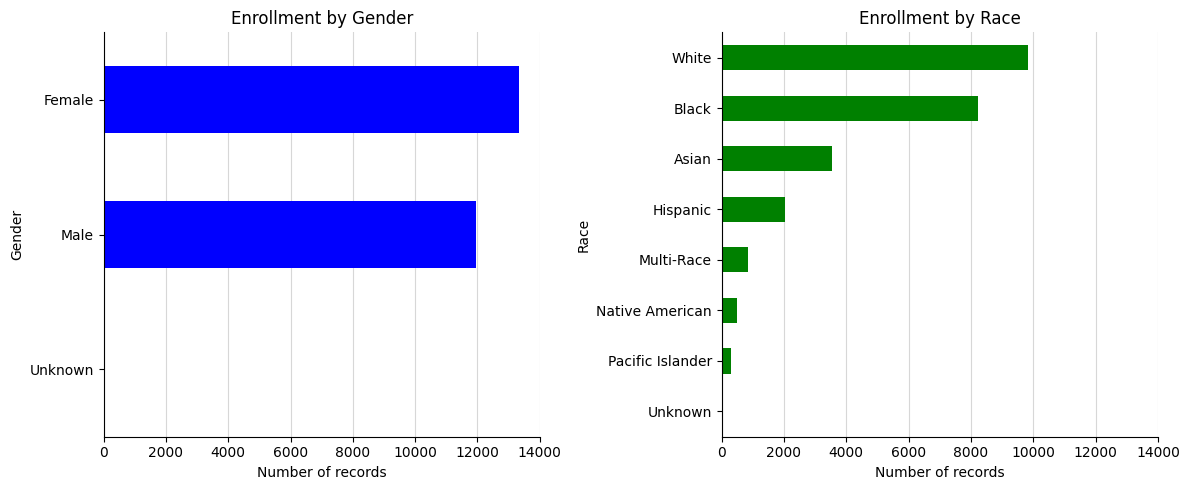

In [ ]:
# Enrollment by Gender and Race
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, col, color in zip(
    axes,
    ["Gender", "Race"],
    ["Blue", "Green"]
):
    counts = df[col].fillna("Missing").value_counts().sort_values()

    counts.plot(kind="barh", ax=ax, color=color)

    ax.set_xticks(range(0, 14001, 2000))
    ax.grid(axis="x", linestyle="-", alpha=0.5)
    ax.set_axisbelow(True)

    ax.set_title(f"Enrollment by {col}")
    ax.set_xlabel("Number of records")
    ax.set_ylabel(col)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig("visualization1_gender_race.png", dpi=300, bbox_inches="tight")
plt.show()



These charts compare the recorded enrollment across gender and race categories. The largest category was Female Gender, with 13350 records.

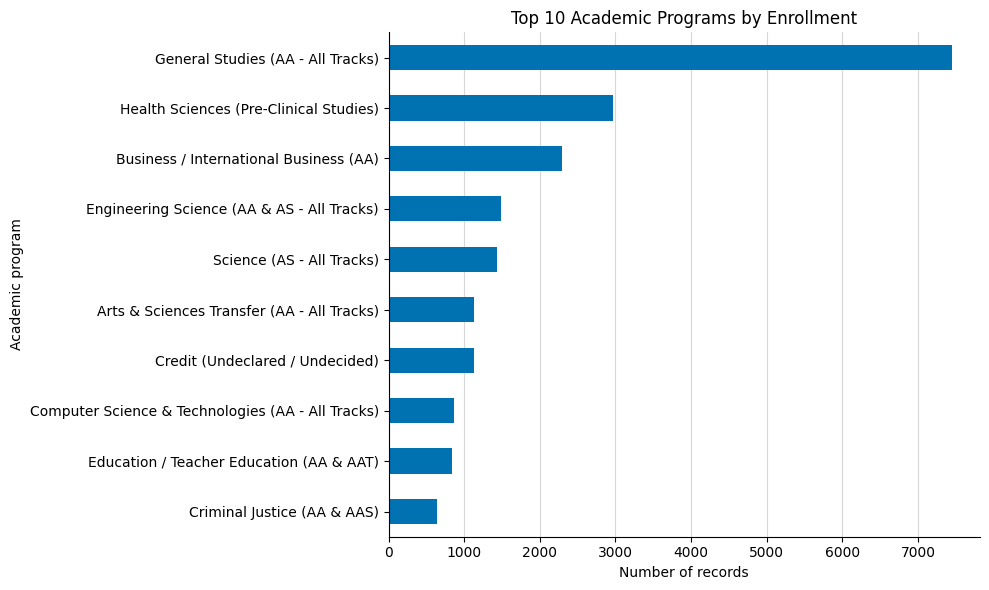

In [ ]:
# The top 10 accadamic programs by enrollement
programs = (
    df["MC Program Description"]
    .fillna("Missing")
    .value_counts()
    .head(10)
    .sort_values()
)

fig, ax = plt.subplots(figsize=(10, 6))

programs.plot(kind="barh", ax=ax, color="#0072B2")

ax.set_xticks(range(0, 7001, 1000))
ax.grid(axis="x", linestyle="-", alpha=0.5)
ax.set_axisbelow(True)

ax.set_title("Top 10 Academic Programs by Enrollment")
ax.set_xlabel("Number of records")
ax.set_ylabel("Academic program")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig("visualization2_programs.png", dpi=300, bbox_inches="tight")
plt.show()



This chart compares the 10 programs with the highest recorded counts. Genereal Studies (AA - All Tracks) had the highest count, followed by Health Sciences (Pre-Clinical Studies). The General Studies (AA - All Tracks) programs have noticeably higher counts than the others.

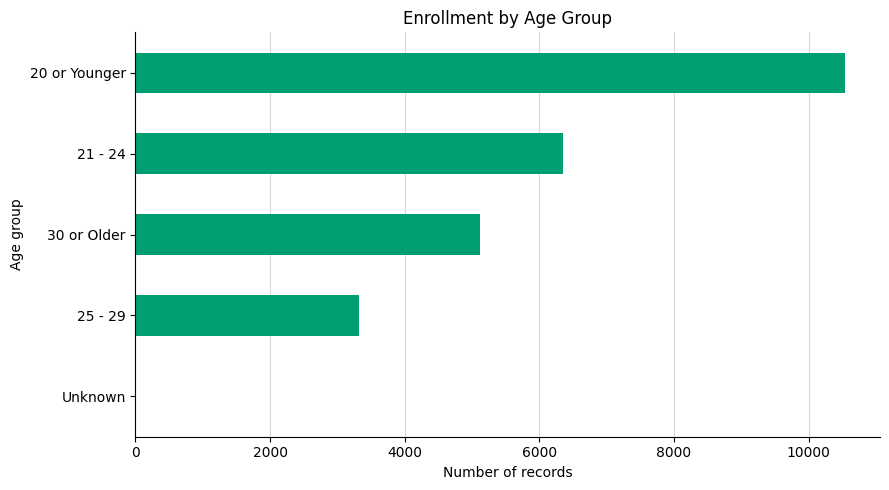

In [ ]:
# Enrollment by age group
age_counts = (
    df["Age Group"]
    .fillna("Missing")
    .value_counts()
    .sort_values()
)

fig, ax = plt.subplots(figsize=(9, 5))

age_counts.plot(kind="barh", ax=ax, color="#009E73")

ax.set_xticks(range(0, 10001, 2000))
ax.grid(axis="x", linestyle="-", alpha=0.5)
ax.set_axisbelow(True)

ax.set_title("Enrollment by Age Group")
ax.set_xlabel("Number of records")
ax.set_ylabel("Age group")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig("visualization3_age_groups.png", dpi=300, bbox_inches="tight")
plt.show()



Enrollment varied across the age groups in the dataset. The age group 20 or younger had the highest recorded count, while the Unknoen age group had the lowest.

In conclusion, this project helped me better understand Montgomery College’s 2015 enrollment data. I found that female students had the highest recorded count, General Studies was the most common program, and students aged 20 or younger were the largest age group.

Overall, the charts helped me see how enrollment varied across different groups. However, the data only shows patterns from 2015 and cannot explain why these differences occurred.